In [10]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [11]:
files = list(Path("../data").rglob("*.xls*"))
print(f'Number of files: {len(files)}')

for file in files:
    print(file)

Number of files: 18
../data/2025/23MARCH25-1MAY25.xls
../data/2025/AUG 2025.xls
../data/2025/DEC 2025.xls
../data/2025/JAN 2025.xls
../data/2025/JULY 2025.xls
../data/2025/JuNE 2025.xls
../data/2025/MAY 2025.xls
../data/2025/NOV2025.xls
../data/2025/OCT 2025.xls
../data/2025/SEP 2025.xls
../data/2026/APR20-MAY42026.xls
../data/2026/August 2026.xls
../data/2026/FEB 2026.xls
../data/2026/JAN 2026.xls
../data/2026/JULY2026.xls
../data/2026/june 2026.xls
../data/2026/MARCH-APR 20.xls
../data/2026/MAY 2026.xls


In [12]:
df = pd.read_csv(files[0], sep='\t')
df.columns

Index(['Date(dd/mm/yy)', 'Time(HH:MM)', 'W Direction(Deg)', 'Temp(Deg C)',
       'R Humidity(%)', 'Solar(CCM)', 'B Pressure(mmHg)', 'Spd(Km/hr)',
       'Rain(mm)', 'Unnamed: 9'],
      dtype='str')

In [13]:
solar_data = []

for file in files:
    df = pd.read_csv(file, sep="\t")

    df = df[[
        "Date(dd/mm/yy)",
        "Time(HH:MM)",
        "Solar(CCM)"
    ]]

    solar_data.append(df)

solar_data = pd.concat(solar_data, ignore_index=True)

print(solar_data.head())
print(solar_data.info())

  Date(dd/mm/yy) Time(HH:MM) Solar(CCM)
0       24/03/25       13:57        NaN
1       24/03/25       14:00        1.4
2       24/03/25       14:27        NaN
3       24/03/25       14:46        NaN
4       24/03/25       15:23        NaN
<class 'pandas.DataFrame'>
RangeIndex: 12692 entries, 0 to 12691
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date(dd/mm/yy)  12692 non-null  str   
 1   Time(HH:MM)     12692 non-null  str   
 2   Solar(CCM)      12438 non-null  object
dtypes: object(1), str(2)
memory usage: 297.6+ KB
None


In [14]:
print("Total observations:", len(solar_data))

print("\nMissing values:")
print(solar_data.isnull().sum())

print("\nData types:")
print(solar_data.dtypes)

print("\nUnique non-numeric values:")
print(
    solar_data[
        pd.to_numeric(
            solar_data["Solar(CCM)"],
            errors="coerce"
        ).isna()
    ]["Solar(CCM)"].value_counts()
)

Total observations: 12692

Missing values:
Date(dd/mm/yy)      0
Time(HH:MM)         0
Solar(CCM)        254
dtype: int64

Data types:
Date(dd/mm/yy)       str
Time(HH:MM)          str
Solar(CCM)        object
dtype: object

Unique non-numeric values:
Solar(CCM)
-Transfer Error-    77
Name: count, dtype: int64


In [15]:
solar_data["Solar(CCM)"] = pd.to_numeric(
    solar_data["Solar(CCM)"],
    errors="coerce"
)

solar_clean = solar_data.dropna(subset=["Solar(CCM)"]).copy()

solar_clean["Datetime"] = pd.to_datetime(
    solar_clean["Date(dd/mm/yy)"].astype(str) + " " +
    solar_clean["Time(HH:MM)"].astype(str),
    dayfirst=True,
    format="mixed",
    errors="coerce"
)

solar_clean = solar_clean.dropna(subset=["Datetime"])
solar_clean = solar_clean.sort_values("Datetime")

print("Observations after cleaning:", len(solar_clean))
print("\nSolar radiation statistics:")
print(solar_clean["Solar(CCM)"].describe())

print("\nMinimum:", solar_clean["Solar(CCM)"].min())
print("Maximum:", solar_clean["Solar(CCM)"].max())

print("\nNegative readings:")
print((solar_clean["Solar(CCM)"] < 0).sum())

print("\nEarliest reading:", solar_clean["Datetime"].min())
print("Latest reading:", solar_clean["Datetime"].max())

Observations after cleaning: 12361

Solar radiation statistics:
count    12361.000000
mean         0.265407
std          6.689981
min          0.000000
25%          0.000000
50%          0.000000
75%          0.200000
max        742.700000
Name: Solar(CCM), dtype: float64

Minimum: 0.0
Maximum: 742.7

Negative readings:
0

Earliest reading: 0110-10-11 08:00:00
Latest reading: 2026-09-07 12:00:00


In [16]:
print(
    solar_clean[
        ["Date(dd/mm/yy)", "Time(HH:MM)", "Datetime", "Solar(CCM)"]
    ].sort_values("Datetime").head(25).to_string(index=False)
)

print("\nDates parsed before 2020:")
print(
    solar_clean.loc[
        solar_clean["Datetime"].dt.year < 2020,
        ["Date(dd/mm/yy)", "Time(HH:MM)", "Datetime"]
    ].to_string(index=False)
)

print("\nYear-wise observation counts:")
print(solar_clean["Datetime"].dt.year.value_counts().sort_index())

Date(dd/mm/yy) Time(HH:MM)            Datetime  Solar(CCM)
          8:00       110.0  110-10-11 08:00:00       742.7
      02/12/24       16:00 2024-12-02 16:00:00         0.2
      02/12/24       17:00 2024-12-02 17:00:00         0.1
      02/12/24       18:00 2024-12-02 18:00:00         0.0
      02/12/24       19:00 2024-12-02 19:00:00         0.0
      02/12/24       20:00 2024-12-02 20:00:00         0.0
      02/12/24       21:00 2024-12-02 21:00:00         0.0
      02/12/24       22:00 2024-12-02 22:00:00         0.0
      02/12/24       23:00 2024-12-02 23:00:00         0.0
      03/12/24        0:00 2024-12-03 00:00:00         0.0
      03/12/24        1:00 2024-12-03 01:00:00         0.0
      03/12/24        2:00 2024-12-03 02:00:00         0.0
      03/12/24        3:00 2024-12-03 03:00:00         0.0
      03/12/24        4:00 2024-12-03 04:00:00         0.0
      03/12/24        5:00 2024-12-03 05:00:00         0.0
      03/12/24        6:00 2024-12-03 06:00:00         0

In [17]:
print(
    solar_data[
        (solar_data["Date(dd/mm/yy)"] == "8:00") |
        (solar_data["Time(HH:MM)"] == "110.0")
    ].to_string(index=False)
)
print("Malformed date rows:")

print(
    solar_clean[
        solar_clean["Datetime"].dt.year < 2020
    ].to_string(index=False)
)

Date(dd/mm/yy) Time(HH:MM)  Solar(CCM)
          8:00       110.0       742.7
Malformed date rows:
Date(dd/mm/yy) Time(HH:MM)  Solar(CCM)           Datetime
          8:00       110.0       742.7 110-10-11 08:00:00


In [18]:
print("1. Original malformed rows:")

print(
    solar_data[
        (solar_data["Date(dd/mm/yy)"] == "8:00") |
        (solar_data["Time(HH:MM)"] == "110.0")
    ].to_string(index=False)
)

print("\n2. All records with incorrectly parsed dates:")

print(
    solar_clean[
        solar_clean["Datetime"].dt.year < 2020
    ].to_string(index=False)
)

1. Original malformed rows:
Date(dd/mm/yy) Time(HH:MM)  Solar(CCM)
          8:00       110.0       742.7

2. All records with incorrectly parsed dates:
Date(dd/mm/yy) Time(HH:MM)  Solar(CCM)           Datetime
          8:00       110.0       742.7 110-10-11 08:00:00


In [19]:
solar_clean = solar_clean[
    solar_clean["Datetime"].dt.year >= 2020
].copy()

print("Observations after removing malformed date:", len(solar_clean))
print("Earliest reading:", solar_clean["Datetime"].min())
print("Latest reading:", solar_clean["Datetime"].max())
print(solar_clean["Solar(CCM)"].describe())

solar_clean["Month"] = solar_clean["Datetime"].dt.to_period("M")

monthly_coverage = (
    solar_clean.groupby("Month")
    .size()
    .reset_index(name="Observations")
)

print(monthly_coverage.to_string(index=False))

Observations after removing malformed date: 12360
Earliest reading: 2024-12-02 16:00:00
Latest reading: 2026-09-07 12:00:00
count    12360.000000
mean         0.205340
std          0.395016
min          0.000000
25%          0.000000
50%          0.000000
75%          0.200000
max          1.600000
Name: Solar(CCM), dtype: float64
  Month  Observations
2024-12           699
2025-01            55
2025-03           175
2025-04           711
2025-05           739
2025-06           715
2025-07           743
2025-08           742
2025-09           717
2025-10           739
2025-11           713
2025-12           739
2026-01           792
2026-02           703
2026-03            36
2026-04           251
2026-05           740
2026-06           715
2026-07           741
2026-08           738
2026-09           157


In [20]:
monthly_solar = (
    solar_clean.groupby("Month")
    .agg(
        Average_Solar=("Solar(CCM)", "mean"),
        Observations=("Solar(CCM)", "count")
    )
    .reset_index()
)

print(monthly_solar.to_string(index=False))

  Month  Average_Solar  Observations
2024-12       0.086552           699
2025-01       0.083636            55
2025-03       0.362286           175
2025-04       0.353305           711
2025-05       0.299594           739
2025-06       0.255385           715
2025-07       0.129610           743
2025-08       0.164151           742
2025-09       0.186192           717
2025-10       0.199188           739
2025-11       0.167602           713
2025-12       0.142355           739
2026-01       0.101515           792
2026-02       0.163727           703
2026-03       0.286111            36
2026-04       0.394422           251
2026-05       0.376216           740
2026-06       0.318741           715
2026-07       0.139946           741
2026-08       0.127100           738
2026-09       0.141401           157


In [21]:
solar_reliable = monthly_solar[
    monthly_solar["Observations"] >= 600
].copy()

solar_reliable["Month"] = solar_reliable["Month"].astype(str)

print(solar_reliable.to_string(index=False))

  Month  Average_Solar  Observations
2024-12       0.086552           699
2025-04       0.353305           711
2025-05       0.299594           739
2025-06       0.255385           715
2025-07       0.129610           743
2025-08       0.164151           742
2025-09       0.186192           717
2025-10       0.199188           739
2025-11       0.167602           713
2025-12       0.142355           739
2026-01       0.101515           792
2026-02       0.163727           703
2026-05       0.376216           740
2026-06       0.318741           715
2026-07       0.139946           741
2026-08       0.127100           738


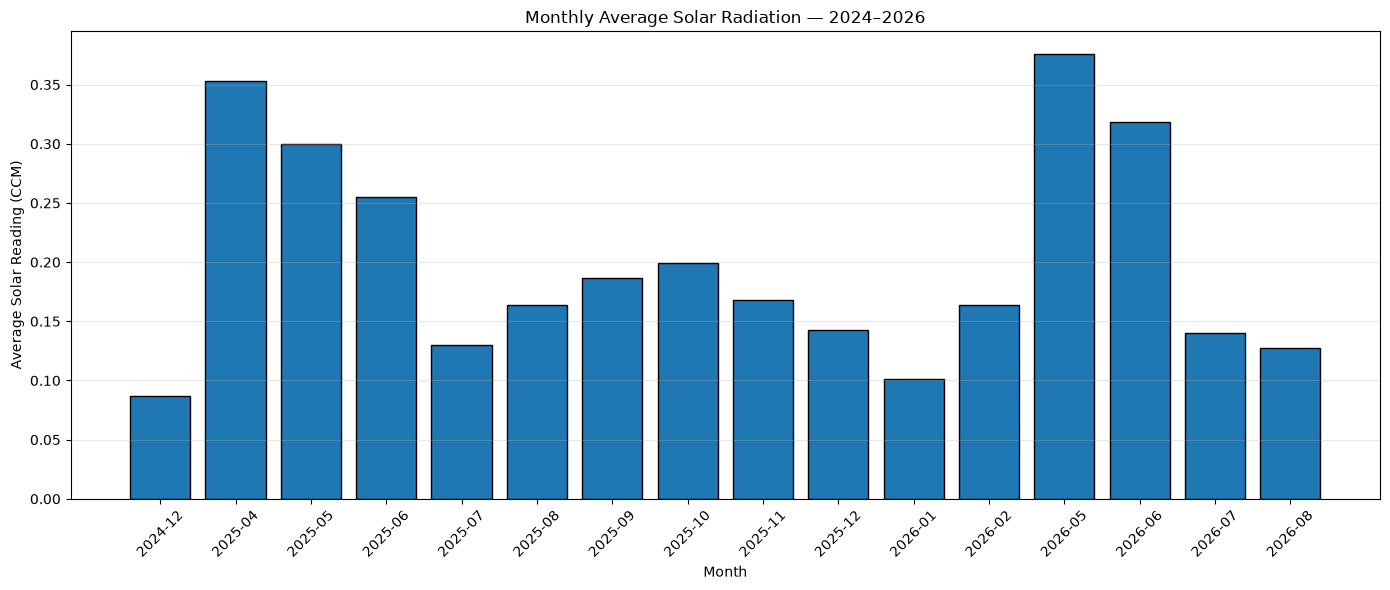

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    solar_reliable["Month"],
    solar_reliable["Average_Solar"],
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Average Solar Reading (CCM)")
plt.title("Monthly Average Solar Radiation — 2024–2026")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
solar_clean = solar_clean.sort_values("Datetime")

print("Duplicate timestamps:",
      solar_clean["Datetime"].duplicated().sum())

print("\nTime difference between consecutive readings:")
print(
    solar_clean["Datetime"]
    .diff()
    .value_counts()
    .head(10)
)

Duplicate timestamps: 89

Time difference between consecutive readings:
Datetime
0 days 01:00:00     12190
0 days 00:00:00        89
0 days 02:00:00        78
80 days 08:00:00        1
49 days 02:00:00        1
Name: count, dtype: int64


In [24]:
duplicate_rows = solar_clean[
    solar_clean["Datetime"].duplicated(keep=False)
].sort_values("Datetime")

print(duplicate_rows[
    ["Datetime", "Solar(CCM)"]
].to_string(index=False))

           Datetime  Solar(CCM)
2026-01-29 19:00:00         0.0
2026-01-29 19:00:00         0.0
2026-01-29 20:00:00         0.0
2026-01-29 20:00:00         0.0
2026-01-29 21:00:00         0.0
2026-01-29 21:00:00         0.0
2026-01-29 22:00:00         0.0
2026-01-29 22:00:00         0.0
2026-01-29 23:00:00         0.0
2026-01-29 23:00:00         0.0
2026-01-30 00:00:00         0.0
2026-01-30 00:00:00         0.0
2026-01-30 01:00:00         0.0
2026-01-30 01:00:00         0.0
2026-01-30 02:00:00         0.0
2026-01-30 02:00:00         0.0
2026-01-30 03:00:00         0.0
2026-01-30 03:00:00         0.0
2026-01-30 04:00:00         0.0
2026-01-30 04:00:00         0.0
2026-01-30 05:00:00         0.0
2026-01-30 05:00:00         0.0
2026-01-30 06:00:00         0.0
2026-01-30 06:00:00         0.0
2026-01-30 07:00:00         0.0
2026-01-30 07:00:00         0.0
2026-01-30 08:00:00         0.0
2026-01-30 08:00:00         0.0
2026-01-30 09:00:00         0.1
2026-01-30 09:00:00         0.1
2026-01-

In [25]:
duplicate_check = (
    solar_clean.groupby("Datetime")["Solar(CCM)"]
    .agg(["count", "nunique"])
)

duplicate_check = duplicate_check[duplicate_check["count"] > 1]

print("Duplicate timestamps:", len(duplicate_check))

print(
    "Timestamps with conflicting readings:",
    (duplicate_check["nunique"] > 1).sum()
)

Duplicate timestamps: 89
Timestamps with conflicting readings: 0


In [26]:
solar_clean = solar_clean.drop_duplicates(
    subset=["Datetime", "Solar(CCM)"]
).copy()

print("Observations after deduplication:", len(solar_clean))
print(
    "Remaining duplicate timestamps:",
    solar_clean["Datetime"].duplicated().sum()
)

Observations after deduplication: 12271
Remaining duplicate timestamps: 0


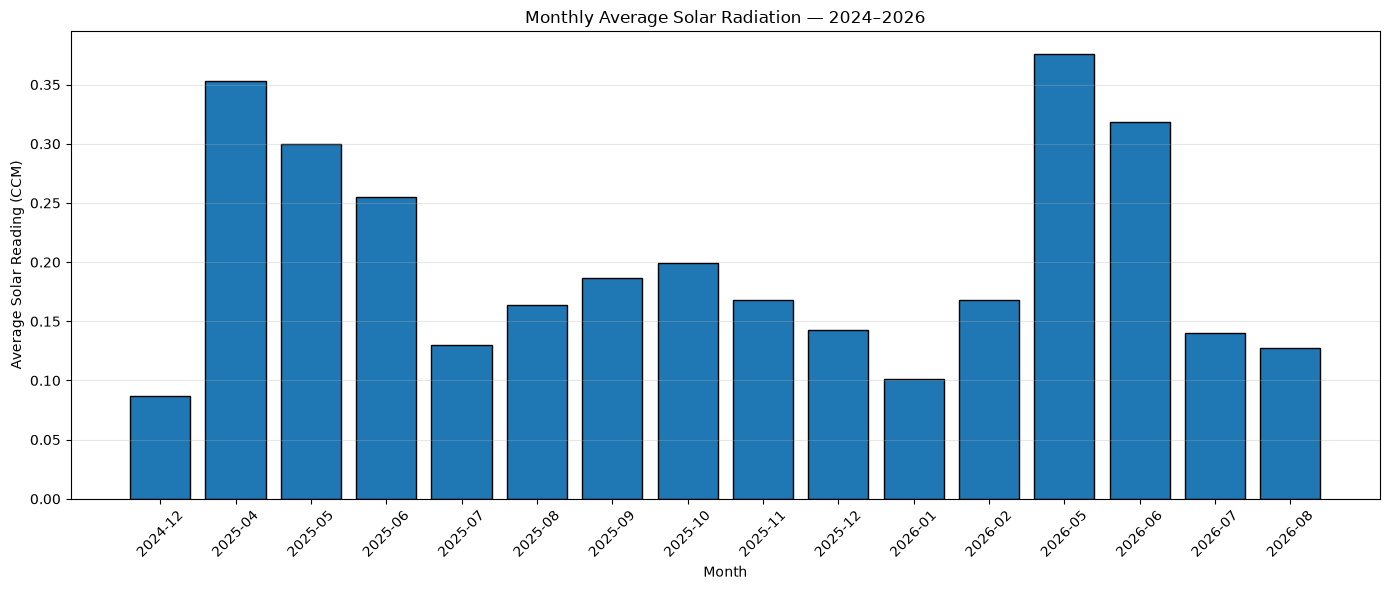

In [27]:
solar_clean["Month"] = solar_clean["Datetime"].dt.to_period("M")

monthly_solar = (
    solar_clean.groupby("Month")
    .agg(
        Average_Solar=("Solar(CCM)", "mean"),
        Observations=("Solar(CCM)", "count")
    )
    .reset_index()
)

solar_reliable = monthly_solar[
    monthly_solar["Observations"] >= 600
].copy()

solar_reliable["Month"] = solar_reliable["Month"].astype(str)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    solar_reliable["Month"],
    solar_reliable["Average_Solar"],
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Average Solar Reading (CCM)")
plt.title("Monthly Average Solar Radiation — 2024–2026")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()